# 第3章：距离度量——原公式 vs skfolio

## 统一实验约定
各章节在项目根目录独立运行，无需安装本项目。公共数据处理与实验辅助见 [notebook_common.py](notebook_common.py)，依赖集中在 [requirement.txt](requirement.txt)。

所有章节读取 `data/hs_funds_prices.parquet`，固定种子42。最近1,260个价格观测中，前1,008个用于训练，后252个用于测试。
`SelectComplete` 排除训练收益中的全部缺失；`DropZeroVariance` 的阈值换算后保持原口径：样本方差（`ddof=1`）大于 `1e-12`。默认使用全部合格基金，测试期不重新筛选资产。
先计算单日收益，再排除共同无效日期，不做填充。测试结果**不是连续、可交易的回测**；价格复权口径尚未确认。

初始化只展示数据摘要；完整资产和排除日期可按需查看 `data.assets`、`data.excluded_test_dates`。`ML4AM_SMOKE=1` 仅供自动化小样本验证，正常运行不设置。

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from notebook_common import load_data, setup_notebook, timed

SEED = 42
RUN_EXPENSIVE = False
setup_notebook(SEED)
data = load_data()
X_train, X_test, assets = data.X_train, data.X_test, data.assets
display(data.summary())

数据模式                          全部合格基金
训练期合格基金数                         488
本次使用基金数                          488
训练收益行数                          1007
训练收益区间       2021-07-14 至 2025-09-04
测试候选区间       2025-09-05 至 2026-09-18
测试候选日期数                          252
测试共同有效日期数                        124
排除测试日期数                          128
测试日期覆盖率                       49.21%
Name: 数据概览, dtype: object

## 1. 角距离
[原项目](Machine_Learning_for_Asset_Managers/ch3_metrics.py)的成对信息度量与README中的距离概念分别核对。
标准角距离为 `sqrt((1-rho)/2)`；绝对和平方版本采用skfolio的归一化约定
`sqrt(1-abs(rho))`、`sqrt(1-rho**2)`，不使用README中错误的括号表达式。

开始：标准角距离


完成：标准角距离，耗时 0.01 秒


开始：绝对角距离


完成：绝对角距离，耗时 0.02 秒


开始：平方角距离


完成：平方角距离，耗时 0.01 秒


,距离,最大误差,耗时秒
0,标准角距离,1.053671e-08,0.014898
1,绝对角距离,1.490116e-08,0.015122
2,平方角距离,2.107342e-08,0.014428


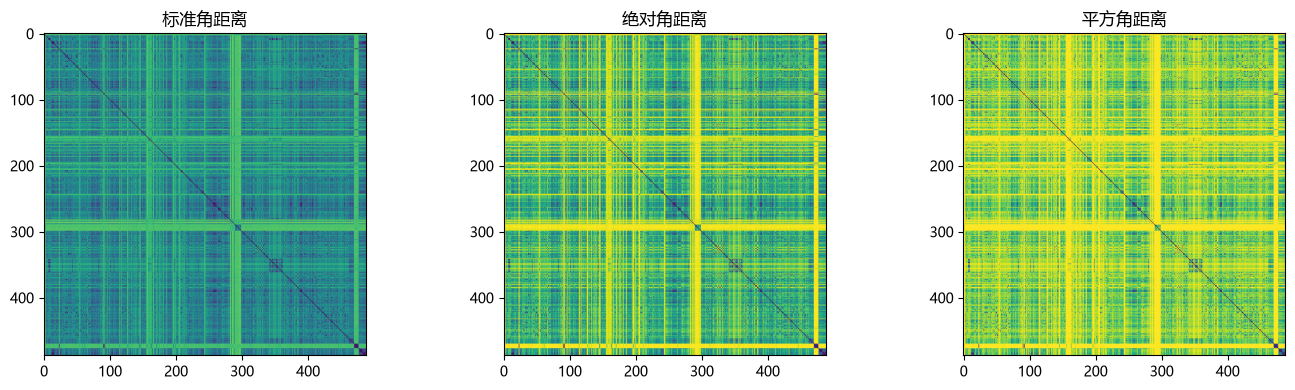

In [2]:
from skfolio.distance import PearsonDistance, MutualInformation, DistanceCorrelation
from skfolio.utils.stats import n_bins_freedman
from Machine_Learning_for_Asset_Managers import ch3_metrics as original
corr = X_train.corr().to_numpy()
rows, distance_matrices = [], {}
for name, kwargs, expected in [
    ('标准角距离', {}, np.sqrt(np.clip((1-corr)/2, 0, 1))),
    ('绝对角距离', {'absolute': True}, np.sqrt(np.clip(1-np.abs(corr), 0, 1))),
    ('平方角距离', {'power': 2}, np.sqrt(np.clip(1-corr**2, 0, 1)))]:
    model, elapsed = timed(name, lambda kwargs=kwargs: PearsonDistance(**kwargs).fit(X_train))
    distance_matrices[name] = model.distance_
    error = np.max(np.abs(expected-model.distance_))
    rows.append({'距离': name, '最大误差': error, '耗时秒': elapsed})
    np.testing.assert_allclose(expected, model.distance_, atol=1e-7)
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, matrix) in zip(axes, distance_matrices.items()):
    ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis'); ax.set_title(name)
plt.tight_layout(); plt.show()

## 2. 双变量受控对照：统一分箱、归一化
选定固定资产集合中的前两只；这一步是成对数值校验，不是全资产矩阵的替代。
原 `numBins` 随两变量相关系数变化；skfolio默认采用Freedman规则，二者不可默认等同。
原 `varInfo` 会覆盖传入的 `bins`，因此以其内部公式为准。

In [3]:
pair = X_train.iloc[:, :2]
x, y = pair.to_numpy().T
rho = np.corrcoef(x, y)[0, 1]
assert abs(rho) < 1, '该固定变量对完全相关，原分箱公式无定义；请显式更换变量对'
bins = original.numBins(len(x), rho)
mi_pair = MutualInformation(n_bins=bins, normalize=True).fit(pair)
pair_result = pd.DataFrame({'原实现': [original.mutualInfo(x, y, norm=True), original.varInfo(x, y, bins, norm=True)],
                           'skfolio': [mi_pair.codependence_[0, 1], mi_pair.distance_[0, 1]]}, index=['归一化互信息', '归一化信息变差'])
print('变量对：', pair.columns.tolist(), '分箱数：', bins)
display(pair_result)
np.testing.assert_allclose(pair_result['原实现'], pair_result['skfolio'], atol=1e-12)

变量对： ['159001.SZ', '159003.SZ'] 分箱数： 9


,原实现,skfolio
归一化互信息,0.028616,0.028616
归一化信息变差,0.990347,0.990347


## 3. 全资产矩阵与默认分箱差异
先展示每只基金的默认分箱数，再运行全资产互信息矩阵。极端分箱数可能造成巨大二维直方图，
默认设置单个直方图400万格的内存保护，超限时明确报告未执行，绝不截断资产或悄悄修改默认分箱。
固定20箱的全资产矩阵作为另外一种明确配置展示。

count     488.000000
mean       88.030738
std       387.906111
min        34.000000
25%        52.000000
50%        62.000000
75%        76.000000
max      8464.000000
dtype: float64

511620.SH    8464
159005.SZ    1529
511360.SH     696
511800.SH     543
511030.SH     251
159003.SZ     219
511690.SH     184
160223.SZ     129
159966.SZ     128
160719.SZ     120
Name: 默认Freedman分箱数, dtype: int64

开始：全资产互信息：固定20箱


完成：全资产互信息：固定20箱，耗时 122.71 秒


默认分箱矩阵未执行：二维直方图超过400万格。可检查数据后显式开启高成本扩展。


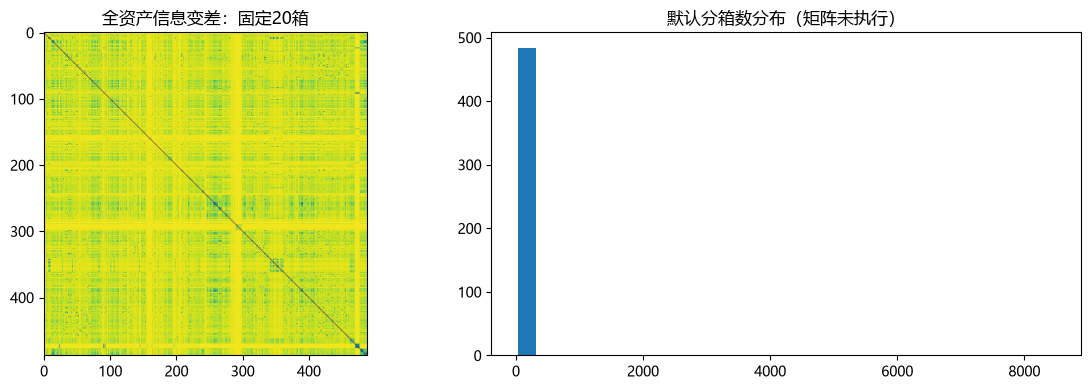

In [4]:
freedman_bins = pd.Series({name: n_bins_freedman(X_train[name].to_numpy()) for name in assets})
display(freedman_bins.describe())
display(freedman_bins.nlargest(10).rename('默认Freedman分箱数'))
mi_fixed, fixed_seconds = timed('全资产互信息：固定20箱', lambda: MutualInformation(n_bins=20).fit(X_train))
if int(freedman_bins.max()) ** 2 <= 4_000_000 or RUN_EXPENSIVE:
    mi_default, default_seconds = timed('全资产互信息：默认Freedman', lambda: MutualInformation().fit(X_train))
    print('两种分箱的平均距离差：', np.nanmean(np.abs(mi_fixed.distance_-mi_default.distance_)))
else:
    mi_default = None
    print('默认分箱矩阵未执行：二维直方图超过400万格。可检查数据后显式开启高成本扩展。')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(mi_fixed.distance_, vmin=0, vmax=1); axes[0].set_title('全资产信息变差：固定20箱')
if mi_default is not None:
    axes[1].imshow(mi_default.distance_, vmin=0, vmax=1); axes[1].set_title('全资产信息变差：默认分箱')
else:
    axes[1].hist(freedman_bins, bins=30); axes[1].set_title('默认分箱数分布（矩阵未执行）')
plt.tight_layout(); plt.show()

In [5]:
if RUN_EXPENSIVE:
    dcorr, _ = timed('全资产距离相关（时间与资产维度均近似平方成本）', lambda: DistanceCorrelation().fit(X_train))
    display(pd.DataFrame(dcorr.distance_, index=assets, columns=assets).iloc[:8, :8])
else:
    print('全资产距离相关扩展未执行；不以少量资产结果冒充全量矩阵。')

全资产距离相关扩展未执行；不以少量资产结果冒充全量矩阵。


## 结论阅读
角距离受控对照应接近浮点精度；互信息差异先检查分箱和归一化。
信息相依性不等于可预测性，距离矩阵也不一定对应可用于Ward的欧氏嵌入。